# Malaria Cell Classification: Custom CNN vs EfficientNetB0
Binary classification of blood cell images (Parasitized / Uninfected).
Compared on Accuracy, Precision, Recall, F1, parameters, and training time.
In medical screening, **Recall** matters most: a missed infection (false negative) is the costliest error.

In [11]:
import os, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

SEED = 42
IMG_SIZE = 128
BATCH = 64
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TF version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

TF version: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


- `Uninfected = 0`
- `Parasitized = 1`

In [12]:
for root, dirs, files in os.walk("/kaggle/input"):
    print(root, "->", dirs[:5], len(files), "files")
    if root.count("/") > 6: break

/kaggle/input -> ['datasets'] 0 files
/kaggle/input/datasets -> ['iarunava'] 0 files
/kaggle/input/datasets/iarunava -> ['cell-images-for-detecting-malaria'] 0 files
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria -> ['cell_images'] 0 files
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images -> ['Parasitized', 'Uninfected', 'cell_images'] 0 files
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Parasitized -> [] 13780 files


In [13]:

BASE = "/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images"

classes = {"Uninfected": 0, "Parasitized": 1}
rows = []
for cls, label in classes.items():
    folder = os.path.join(BASE, cls)
    for f in os.listdir(folder):
        if f.lower().endswith(".png"):
            rows.append((os.path.join(folder, f), label))

df = pd.DataFrame(rows, columns=["path", "label"])
df = df.drop_duplicates(subset="path").reset_index(drop=True)

print("Total images:", len(df))
print(df["label"].value_counts().rename({0: "Uninfected", 1: "Parasitized"}))

Total images: 27558
label
Uninfected     13779
Parasitized    13779
Name: count, dtype: int64


In [14]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

for name, d in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"{name}: {len(d)} images | Parasitized ratio = {d['label'].mean():.3f}")

Train: 19290 images | Parasitized ratio = 0.500
Val: 4134 images | Parasitized ratio = 0.500
Test: 4134 images | Parasitized ratio = 0.500


In [15]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, tf.cast(label, tf.float32)

def make_ds(dataframe, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((dataframe["path"].values, dataframe["label"].values))
    if shuffle:
        ds = ds.shuffle(len(dataframe), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, shuffle=True)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)

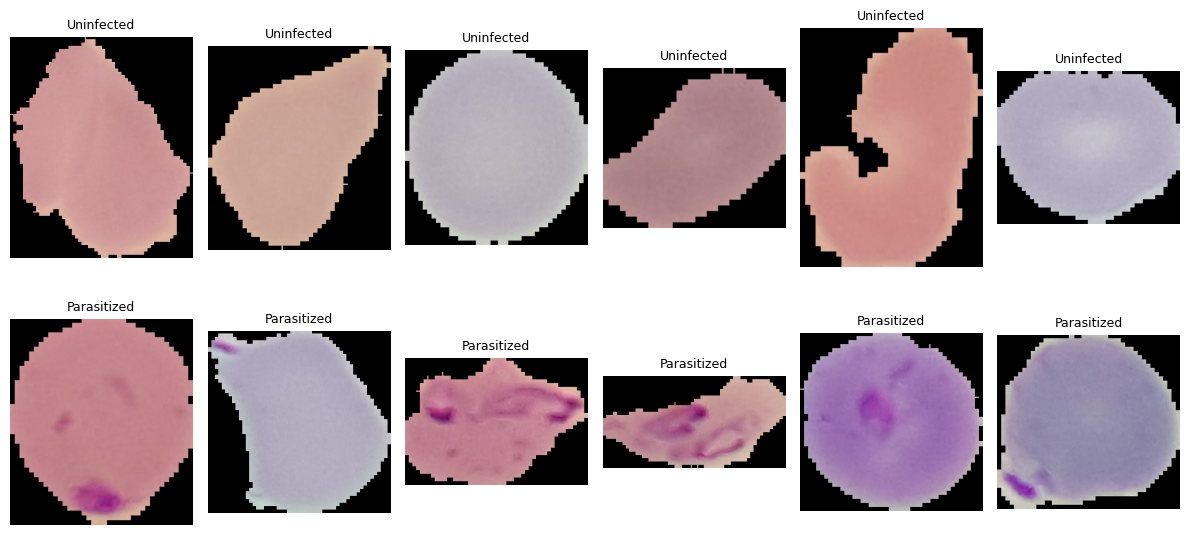

In [16]:
names = {0: "Uninfected", 1: "Parasitized"}
sample = df.groupby("label").sample(6, random_state=SEED)

plt.figure(figsize=(12, 6))
for i, (_, r) in enumerate(sample.iterrows()):
    plt.subplot(2, 6, i + 1)
    plt.imshow(plt.imread(r["path"])); plt.axis("off")
    plt.title(names[r["label"]], fontsize=9)
plt.tight_layout(); plt.show()

## 3. Custom CNN
Augmentation, 3x (Conv, BatchNorm, MaxPool), GlobalAveragePooling, Dense, Dropout, Sigmoid output.

In [17]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

def build_cnn():
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inp)
    x = layers.Rescaling(1./255)(x)
    for filters in [32, 64, 128]:
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out, name="custom_cnn")

cnn = build_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss="binary_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
cb = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

t0 = time.time()
hist_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=cb)
cnn_time = time.time() - t0
print(f"CNN training time: {cnn_time/60:.1f} min")

Epoch 1/20
302/302 ━━━━━━━━━━━━━━━━━━━━ 29s 86ms/step - accuracy: 0.8442 - loss: 0.3628 - val_accuracy: 0.5000 - val_loss: 2.8496 - learning_rate: 0.0010
Epoch 2/20
302/302 ━━━━━━━━━━━━━━━━━━━━ 25s 82ms/step - accuracy: 0.9410 - loss: 0.1833 - val_accuracy: 0.5501 - val_loss: 0.9174 - learning_rate: 0.0010
Epoch 3/20
302/302 ━━━━━━━━━━━━━━━━━━━━ 25s 81ms/step - accuracy: 0.9468 - loss: 0.1662 - val_accuracy: 0.9272 - val_loss: 0.2213 - learning_rate: 0.0010
Epoch 4/20
302/302 ━━━━━━━━━━━━━━━━━━━━ 25s 82ms/step - accuracy: 0.9495 - loss: 0.1544 - val_accuracy: 0.5694 - val_loss: 0.7024 - learning_rate: 0.0010
Epoch 5/20
302/302 ━━━━━━━━━━━━━━━━━━━━ 25s 82ms/step - accuracy: 0.9525 - loss: 0.1482 - val_accuracy: 0.8914 - val_loss: 0.2756 - learning_rate: 0.0010
Epoch 6/20
302/302 ━━━━━━━━━━━━━━━━━━━━ 25s 82ms/step - accuracy: 0.9528 - loss: 0.1385 - val_accuracy: 0.9567 - val_loss: 0.1257 - learning_rate: 5.0000e-04
Epoch 7/20
302/302 ━━━━━━━━━━━━━━━━━━━━ 25s 82ms/step - accuracy: 0.9560

## 4. EfficientNetB0 (Transfer Learning)
Phase 1: train the new head with the base frozen.
Phase 2: fine-tune the last 30 layers with a small learning rate (BatchNorm stays frozen).

In [19]:
def build_effnet():
    base = keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False

    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inp)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inp, out, name="efficientnetb0"), base

eff, base = build_effnet()
eff.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss="binary_crossentropy", metrics=["accuracy"])

t0 = time.time()
hist_eff1 = eff.fit(train_ds, validation_data=val_ds, epochs=8,
                    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                                             restore_best_weights=True)])
eff_time1 = time.time() - t0
print(f"Phase 1 time: {eff_time1/60:.1f} min")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8


E0000 00:00:1795456418.630910      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnetb0_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


302/302 ━━━━━━━━━━━━━━━━━━━━ 31s 72ms/step - accuracy: 0.8448 - loss: 0.3556 - val_accuracy: 0.9008 - val_loss: 0.2594
Epoch 2/8
302/302 ━━━━━━━━━━━━━━━━━━━━ 19s 63ms/step - accuracy: 0.8966 - loss: 0.2624 - val_accuracy: 0.9202 - val_loss: 0.2215
Epoch 3/8
302/302 ━━━━━━━━━━━━━━━━━━━━ 19s 62ms/step - accuracy: 0.9042 - loss: 0.2459 - val_accuracy: 0.9240 - val_loss: 0.2092
Epoch 4/8
302/302 ━━━━━━━━━━━━━━━━━━━━ 18s 61ms/step - accuracy: 0.9073 - loss: 0.2362 - val_accuracy: 0.9277 - val_loss: 0.2052
Epoch 5/8
302/302 ━━━━━━━━━━━━━━━━━━━━ 19s 61ms/step - accuracy: 0.9114 - loss: 0.2279 - val_accuracy: 0.9282 - val_loss: 0.2019
Epoch 6/8
302/302 ━━━━━━━━━━━━━━━━━━━━ 19s 61ms/step - accuracy: 0.9135 - loss: 0.2272 - val_accuracy: 0.9291 - val_loss: 0.2040
Epoch 7/8
302/302 ━━━━━━━━━━━━━━━━━━━━ 19s 62ms/step - accuracy: 0.9123 - loss: 0.2260 - val_accuracy: 0.9286 - val_loss: 0.1924
Epoch 8/8
302/302 ━━━━━━━━━━━━━━━━━━━━ 18s 61ms/step - accuracy: 0.9143 - loss: 0.2222 - val_accuracy: 0.92

In [20]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

eff.compile(optimizer=keras.optimizers.Adam(1e-5),
            loss="binary_crossentropy", metrics=["accuracy"])

t0 = time.time()
hist_eff2 = eff.fit(train_ds, validation_data=val_ds, epochs=10,
                    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                                             restore_best_weights=True)])
eff_time2 = time.time() - t0
eff_time = eff_time1 + eff_time2
print(f"Fine-tuning time: {eff_time2/60:.1f} min | Total: {eff_time/60:.1f} min")

Epoch 1/10


E0000 00:00:1795456603.693859      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnetb0_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


302/302 ━━━━━━━━━━━━━━━━━━━━ 33s 75ms/step - accuracy: 0.9164 - loss: 0.2165 - val_accuracy: 0.9335 - val_loss: 0.1822
Epoch 2/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 21s 69ms/step - accuracy: 0.9229 - loss: 0.2015 - val_accuracy: 0.9369 - val_loss: 0.1764
Epoch 3/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 21s 68ms/step - accuracy: 0.9288 - loss: 0.1910 - val_accuracy: 0.9383 - val_loss: 0.1715
Epoch 4/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 20s 67ms/step - accuracy: 0.9332 - loss: 0.1812 - val_accuracy: 0.9417 - val_loss: 0.1718
Epoch 5/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 20s 68ms/step - accuracy: 0.9350 - loss: 0.1770 - val_accuracy: 0.9415 - val_loss: 0.1639
Epoch 6/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 21s 68ms/step - accuracy: 0.9388 - loss: 0.1674 - val_accuracy: 0.9432 - val_loss: 0.1616
Epoch 7/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 20s 67ms/step - accuracy: 0.9395 - loss: 0.1639 - val_accuracy: 0.9456 - val_loss: 0.1623
Epoch 8/10
302/302 ━━━━━━━━━━━━━━━━━━━━ 20s 68ms/step - accuracy: 0.9400 - loss: 0.1580 - val_accurac

## 5. Test Set Evaluation
Both models are evaluated on the same unseen test set.

In [22]:
def evaluate(model, name, train_time):
    y_true = np.concatenate([y.numpy() for _, y in test_ds]).astype(int)
    probs = model.predict(test_ds, verbose=0).ravel()
    y_pred = (probs >= 0.5).astype(int)
    res = {
        "Model": name,
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall":    recall_score(y_true, y_pred),
        "F1":        f1_score(y_true, y_pred),
        "Params":    model.count_params(),
        "Train time (min)": round(train_time / 60, 1),
    }
    print(f"\n===== {name} =====")
    print(classification_report(y_true, y_pred,
                                target_names=["Uninfected", "Parasitized"], digits=4))
    return res, confusion_matrix(y_true, y_pred)

res_cnn, cm_cnn = evaluate(cnn, "Custom CNN", cnn_time)
res_eff, cm_eff = evaluate(eff, "EfficientNetB0", eff_time)


===== Custom CNN =====
              precision    recall  f1-score   support

  Uninfected     0.9478    0.9748    0.9611      2067
 Parasitized     0.9741    0.9463    0.9600      2067

    accuracy                         0.9606      4134
   macro avg     0.9609    0.9606    0.9606      4134
weighted avg     0.9609    0.9606    0.9606      4134


===== EfficientNetB0 =====
              precision    recall  f1-score   support

  Uninfected     0.9369    0.9415    0.9392      2067
 Parasitized     0.9412    0.9366    0.9389      2067

    accuracy                         0.9390      4134
   macro avg     0.9391    0.9390    0.9390      4134
weighted avg     0.9391    0.9390    0.9390      4134



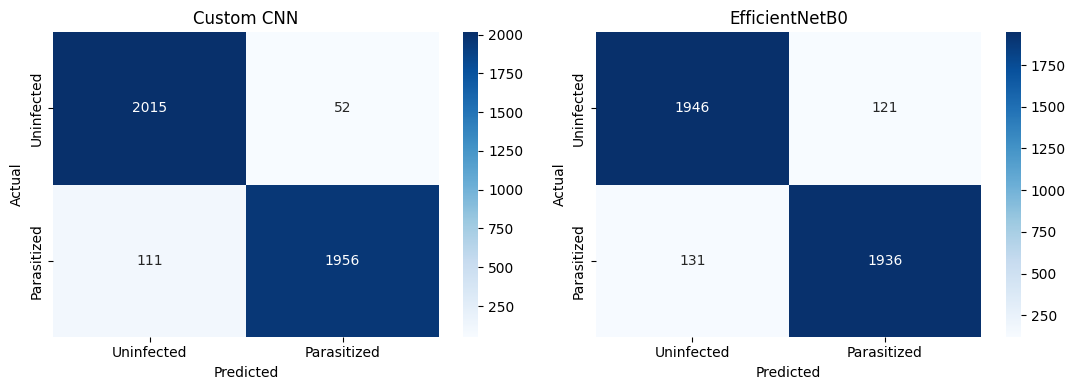

False Negatives -> CNN: 111 | EfficientNet: 131


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, cm, title in zip(axes, [cm_cnn, cm_eff], ["Custom CNN", "EfficientNetB0"]):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Uninfected", "Parasitized"],
                yticklabels=["Uninfected", "Parasitized"])
    ax.set_title(title); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

print(f"False Negatives -> CNN: {cm_cnn[1,0]} | EfficientNet: {cm_eff[1,0]}")

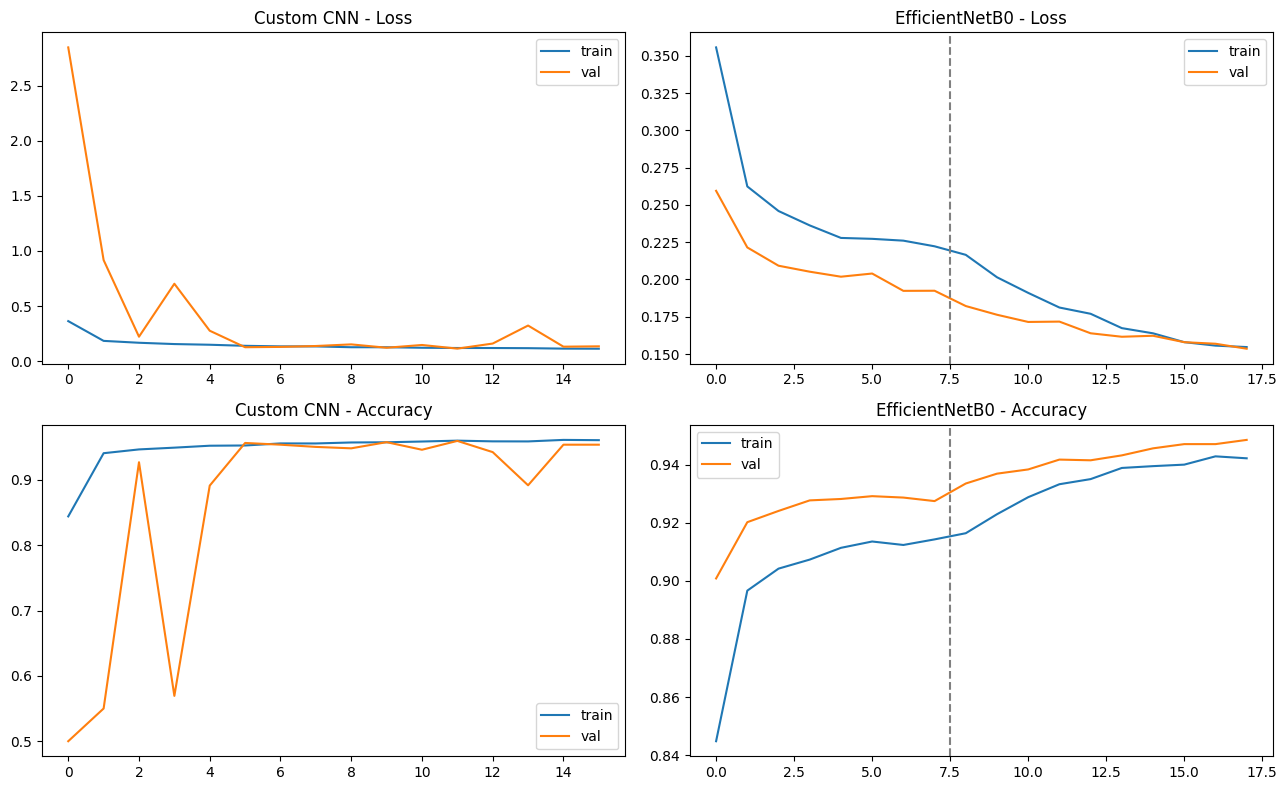

In [24]:
def merge(*hists):
    out = {}
    for h in hists:
        for k, v in h.history.items():
            out.setdefault(k, []).extend(v)
    return out

h_cnn = hist_cnn.history
h_eff = merge(hist_eff1, hist_eff2)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for col, (h, name) in enumerate([(h_cnn, "Custom CNN"), (h_eff, "EfficientNetB0")]):
    axes[0, col].plot(h["loss"], label="train"); axes[0, col].plot(h["val_loss"], label="val")
    axes[0, col].set_title(f"{name} - Loss"); axes[0, col].legend()
    axes[1, col].plot(h["accuracy"], label="train"); axes[1, col].plot(h["val_accuracy"], label="val")
    axes[1, col].set_title(f"{name} - Accuracy"); axes[1, col].legend()
for row in range(2):  # dashed line = start of fine-tuning
    axes[row, 1].axvline(len(hist_eff1.history["loss"]) - 0.5, color="gray", ls="--")
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

In [26]:
results = pd.DataFrame([res_cnn, res_eff]).set_index("Model")
results["Params"] = results["Params"].map("{:,}".format)
display(results.round(4))
results.to_csv("comparison_results.csv")

cnn.save("custom_cnn.keras")
eff.save("efficientnetb0.keras")

,Accuracy,Precision,Recall,F1,Params,Train time (min)
Model,,,,,,
Custom CNN,0.9606,0.9741,0.9463,0.9600,"110,785",6.7
EfficientNetB0,0.9390,0.9412,0.9366,0.9389,"4,050,852",6.3
